# VALORA AI — EDA & Machine Learning Modeling
**Project:** Apartment asking-price estimation in Montenegro  
**Goal:** Explore the updated property dataset, clean the apartment listings, and compare two simple prediction models.

The dataset includes online listings, professional appraisals, and generated examples. For apartment price prediction, I use real online listings only. Appraisals are kept in the original dataset for separate future analysis.


## 1. Load and inspect the dataset

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

In [15]:
# Upload the dataset
uploaded = files.upload()

Saving VALORA_AI_FINAL_COLAB.csv to VALORA_AI_FINAL_COLAB (2).csv


In [16]:
# Read the updated dataset
filename = next(iter(uploaded))
df = pd.read_csv(filename, low_memory=False)
# Use English column names throughout the notebook
df = df.rename(columns={'izvor': 'source', 'sobe': 'bedrooms', 'kupatila': 'bathrooms', 'lokacija': 'location', 'naslov': 'title', 'opis': 'description', 'provjera': 'verification'})
print('Dataset size:', df.shape)


Dataset size: (6913, 59)


The updated dataset contains online listings, professional appraisals and synthetic examples. I will check the columns and data quality before selecting real apartments for my analysis.


In [17]:
# Check the first 5 rows
df.head()

,listing_id,source,property_type,price_eur,area_m2,cijena_po_m2,bedrooms,bathrooms,location,city,...,Land_Area_m2,Bedrooms,Floor,Condition,Year_Built,Price_per_m2_EUR,Data_Source,is_synthetic,price_per_m2_calculated,has_price_and_area
0,2778761,Realitica,kuća,650000.0,250.0,2600.00,NaN,NaN,"Bar, Bar,",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,2600.000000,True
1,2961851,Realitica,kuća,520000.0,95.0,5473.68,NaN,NaN,"Baošići,",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,5473.684211,True
2,3000522,Realitica,kuća,580000.0,314.0,1847.13,NaN,NaN,"Bijela,",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,1847.133758,True
3,3000970,Realitica,kuća,580000.0,285.0,2035.09,NaN,NaN,"Đenovići,",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,2035.087719,True
4,3001059,Realitica,kuća,320000.0,149.0,2147.65,NaN,NaN,"Podi,",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,False,2147.651007,True


Here I can see the first five properties and the information available for each one.

In [18]:
# Check the columns and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6913 entries, 0 to 6912
Data columns (total 59 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   listing_id                  5986 non-null   object 
 1   source                      3986 non-null   object 
 2   property_type               6911 non-null   object 
 3   price_eur                   6401 non-null   float64
 4   area_m2                     6129 non-null   float64
 5   cijena_po_m2                3986 non-null   float64
 6   bedrooms                    3454 non-null   float64
 7   bathrooms                   386 non-null    float64
 8   location                    3986 non-null   object 
 9   city                        6825 non-null   object 
 10  title                       3986 non-null   object 
 11  url                         1986 non-null   object 
 12  description                 549 non-null    object 
 13  verification                3986 

This shows the column names, data types and how many values are filled in.

In [19]:
# Check for missing values
df.isnull().sum()

,0
listing_id,927
source,2927
property_type,2
price_eur,512
area_m2,784
cijena_po_m2,2927
bedrooms,3459
bathrooms,6527
location,2927
city,88


This table shows missing values in each column. I will check the important columns before cleaning the data.

In [20]:
# Check the summary statistics
df.describe()

,price_eur,area_m2,cijena_po_m2,bedrooms,bathrooms,simulated_year_built,simulated_floor,simulated_land_area_m2,land_area_m2,valuation_year,...,Listing_ID,Property_Type,Land_Area_m2,Bedrooms,Floor,Condition,Year_Built,Price_per_m2_EUR,Data_Source,price_per_m2_calculated
count,6.401000e+03,6129.000000,3.986000e+03,3454.000000,386.000000,2000.000000,2000.000000,1000.000000,208.000000,440.000000,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.123000e+03
mean,2.389718e+05,116.378769,4.299608e+03,2.814708,1.316062,1996.921500,3.097000,823.213000,1444.870404,2020.420455,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.519165e+03
std,4.592399e+05,83.095581,6.713776e+04,1.544533,0.570806,17.313411,2.190888,408.121105,5600.596749,3.055752,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.418864e+04
min,1.200000e+03,1.000000,5.130000e+00,0.000000,1.000000,1965.000000,0.000000,100.000000,1.002000,2016.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.128205e+00
25%,1.000000e+05,57.000000,9.745200e+02,2.000000,1.000000,1982.000000,1.000000,471.250000,4.168000,2018.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.524591e+02
50%,1.530000e+05,91.600000,1.852940e+03,3.000000,1.000000,1998.000000,3.000000,842.000000,30.500000,2019.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.755725e+03
75%,2.454710e+05,149.000000,2.997767e+03,4.000000,2.000000,2012.000000,4.000000,1185.250000,310.125000,2025.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.938096e+03
max,1.318300e+07,948.000000,3.000000e+06,20.000000,5.000000,2026.000000,8.000000,1499.000000,28749.625000,2026.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000e+06


This table gives a quick summary of the numbers. Mean is the average, 50% is the median, and min and max show the smallest and largest values. Very high or low values might need checking.

In [21]:
# Check for duplicate rows
df.duplicated().sum()

np.int64(0)

This tells me how many rows are exactly the same. The same property can still appear more than once with slightly different details.

## 2. Initial data inspection

In [22]:
print('Columns:', df.columns.tolist())
print('Data sources:')
print(df['data_source'].value_counts(dropna=False))
print('Property types:')
print(df['property_type'].value_counts(dropna=False).head(15))
print('Missing values in key columns:')
print(df[['price_eur', 'area_m2', 'city', 'property_type']].isna().sum())
display(df[['price_eur', 'area_m2']].describe())


Columns: ['listing_id', 'source', 'property_type', 'price_eur', 'area_m2', 'cijena_po_m2', 'bedrooms', 'bathrooms', 'location', 'city', 'title', 'url', 'description', 'verification', 'data_origin', 'simulated_condition', 'simulated_year_built', 'simulated_floor', 'simulated_land_area_m2', 'data_source', 'document', 'land_area_m2', 'valuation_year', 'price_per_m2', 'review_status', 'city_suggested', 'quality_check', 'possible_duplicate', 'confirmed_city', 'confirmed_area_m2', 'confirmed_price_eur', 'notes', 'verification_status', 'units_in_appraisal', 'source_note', 'original_area_m2', 'original_market_value_eur', 'residential_area_m2', 'auxiliary_area_m2', 'weighted_valuation_area_m2', 'valuation_includes_land', 'price_per_m2_basis', 'source_pages', 'training_status', 'building_area_m2', 'verified_area_m2', 'verified_market_value_eur', 'Listing_ID', 'Property_Type', 'Land_Area_m2', 'Bedrooms', 'Floor', 'Condition', 'Year_Built', 'Price_per_m2_EUR', 'Data_Source', 'is_synthetic', 'price

,price_eur,area_m2
count,6.401000e+03,6129.000000
mean,2.389718e+05,116.378769
std,4.592399e+05,83.095581
min,1.200000e+03,1.000000
25%,1.000000e+05,57.000000
50%,1.530000e+05,91.600000
75%,2.454710e+05,149.000000
max,1.318300e+07,948.000000


These tables show where the new records came from and how complete the main columns are. Some appraisals do not contain enough information for the apartment model, so I keep them separate.


## 3. Data cleaning and selecting real apartments
I select real apartment listings, convert prices and areas to numbers, and remove implausible records. I do not use synthetic records to train the model. The cleaning limits are preliminary quality checks, not official market limits.

I also correct the city column using recognizable place names from the location field. If a city cannot be confirmed, I label it Unknown rather than guessing.


In [23]:
import re
work = df.copy()
work['property_type_clean'] = work['property_type'].astype('string').str.strip().str.lower()
work['price_eur'] = pd.to_numeric(work['price_eur'], errors='coerce')
work['area_m2'] = pd.to_numeric(work['area_m2'], errors='coerce')
work['bedrooms'] = pd.to_numeric(work['bedrooms'], errors='coerce')

real = work[(work['data_source'] == 'Online listing') &
            (work['is_synthetic'] == False) &
            (work['property_type_clean'].isin(['stan', 'apartment']))].copy()
print('Real apartment listings before cleaning:', len(real))
real = real.drop_duplicates(subset=['source', 'listing_id'])
real = real[real['price_eur'].between(10000, 2000000) & real['area_m2'].between(15, 350)].copy()
real['price_per_m2'] = real['price_eur'] / real['area_m2']
real = real[real['price_per_m2'].between(300, 15000)].copy()
print('Real apartment listings after cleaning:', len(real))
# Correct city labels using the location information when possible.
# Keep the original values for checking later.
real['city_original'] = real['city']
valid_cities = ['Podgorica','Budva','Bar','Kotor','Tivat','Herceg Novi','Ulcinj',
                'Nikšić','Cetinje','Kolašin','Žabljak','Bijelo Polje','Berane',
                'Danilovgrad','Pljevlja','Plav','Rožaje','Mojkovac','Petnjica',
                'Tuzi','Zeta','Andrijevica','Šavnik','Plužine','Gusinje']
aliases = {'Niksic':'Nikšić','Kolasin':'Kolašin','Zabljak':'Žabljak',
           'Rozaje':'Rožaje','Savnik':'Šavnik','Pluzine':'Plužine'}
# Some coastal settlements belong to larger municipalities.
settlements = {'Đenovići':'Herceg Novi', 'Djenovici':'Herceg Novi',
               'Meljine':'Herceg Novi', 'Baošići':'Herceg Novi',
               'Baosici':'Herceg Novi', 'Dobrota':'Kotor',
               'Bečići':'Budva', 'Becici':'Budva', 'Rafailovići':'Budva',
               'Rafailovici':'Budva'}
real['city'] = real['city'].astype('string').str.strip().replace(aliases)
real['city'] = real['city'].where(real['city'].isin(valid_cities))
location_text = real['location'].fillna('').astype(str)
for name, city_name in {**dict.fromkeys(valid_cities), **aliases, **settlements}.items():
    target = city_name if city_name is not None else name
    matches = real['city'].isna() & location_text.str.contains(
        r'(?<!\w)' + re.escape(name) + r'(?!\w)', case=False, regex=True)
    real.loc[matches, 'city'] = target
real['city'] = real['city'].fillna('Unknown')
print('City values still unknown:', (real['city'] == 'Unknown').sum())
display(real[['city', 'location', 'area_m2', 'bedrooms', 'price_eur', 'price_per_m2']].head())


Real apartment listings before cleaning: 2473
Real apartment listings after cleaning: 2432
City values still unknown: 186


,city,location,area_m2,bedrooms,price_eur,price_per_m2
95,Herceg Novi,"Đenovići,",59.0,1.0,154000.0,2610.169492
96,Herceg Novi,"Meljine,",230.0,5.0,1520000.0,6608.695652
97,Kotor,"Kotor, Kotor,",58.0,1.0,320000.0,5517.241379
98,Herceg Novi,"Baošići,",93.0,2.0,220000.0,2365.591398
99,Herceg Novi,"Herceg Novi,",178.0,3.0,550000.0,3089.887640


This table shows apartment listings after cleaning. I excluded synthetic examples and records with suspicious prices or areas. The original dataset is not changed.


## 4. EDA — prices, apartment size, and location

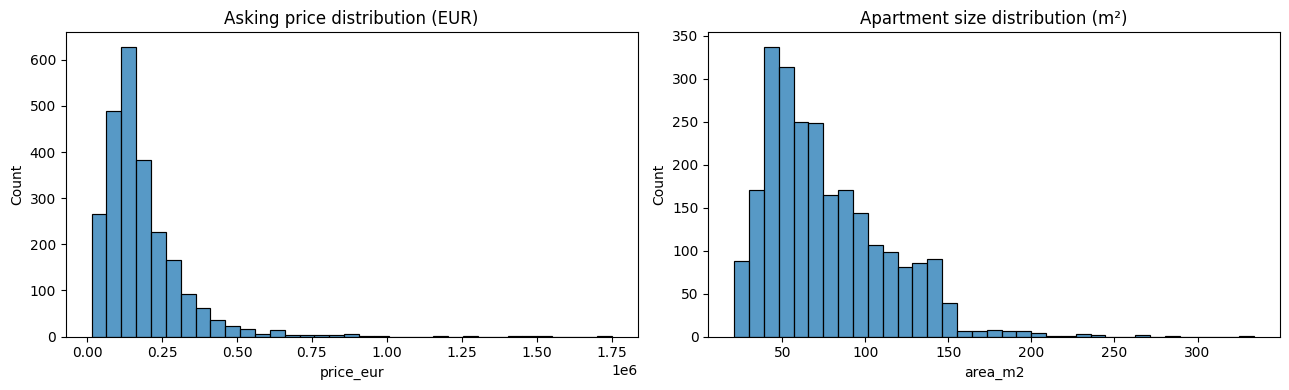

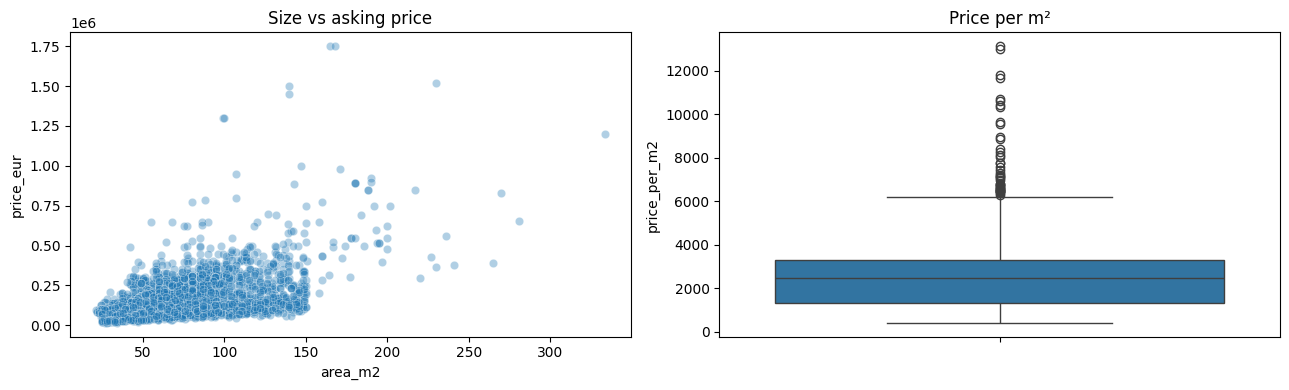

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(real['price_eur'], bins=35, ax=axes[0]); axes[0].set_title('Asking price distribution (EUR)')
sns.histplot(real['area_m2'], bins=35, ax=axes[1]); axes[1].set_title('Apartment size distribution (m²)')
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=real, x='area_m2', y='price_eur', alpha=.35, ax=axes[0])
axes[0].set_title('Size vs asking price')
sns.boxplot(data=real, y='price_per_m2', ax=axes[1]); axes[1].set_title('Price per m²')
plt.tight_layout(); plt.show()

(1)The first charts show how prices and apartment sizes are distributed.

(2)Apartment Size Distribution. Most apartments are between 40 and 80 m². Larger apartments are less common, and only a few are over 200 m².

(3)The scatter plot compares size and price. The scatter plot shows a positive relationship between property size and price. Larger properties usually cost more, but there are some outliers with much higher prices.

(4)The box plot shows that most property prices are around €3,000 per m². There are several outliers with much higher prices that should be checked before modeling.

Apartment listings by city:


,count
city_model,
Podgorica,541
Budva,279
Unknown,186
Bar,124
Herceg Novi,119
Tivat,108
Kotor,102
Kolašin,100
Ulcinj,93


,listings,median_eur_m2
city_model,,
Tivat,108,3887.397465
Kotor,102,3447.198276
Budva,279,3400.000000
Herceg Novi,119,3071.428571
Podgorica,541,2777.777778
Bar,124,2564.738292
Kolašin,100,2403.535980
Ulcinj,93,2098.765432
Žabljak,58,2064.988334


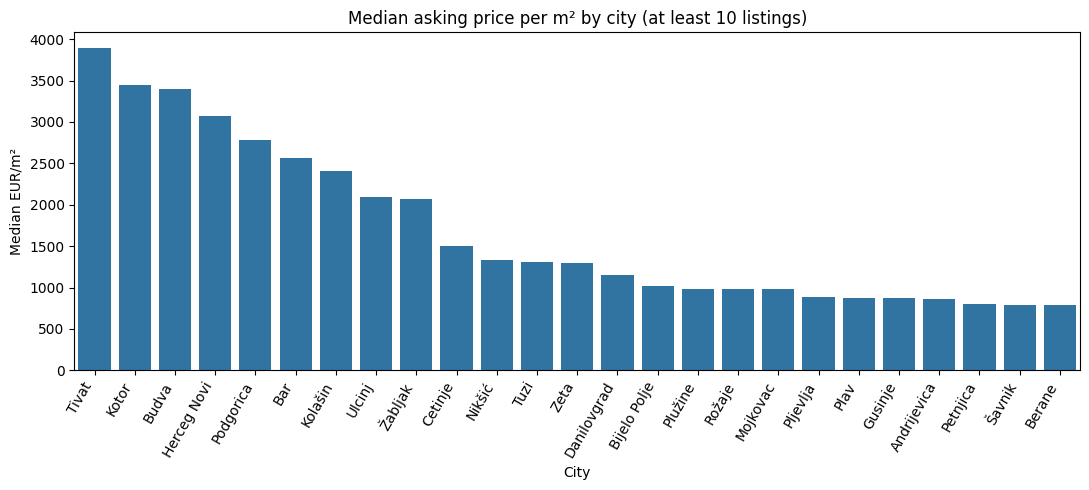

In [25]:
# Keep only actual city names: labels such as "stan 1 sobe" are not cities.
valid_cities = ['Podgorica','Budva','Bar','Kotor','Tivat','Herceg Novi','Ulcinj','Nikšić','Cetinje','Kolašin','Žabljak','Bijelo Polje','Berane','Danilovgrad','Pljevlja','Plav','Rožaje','Mojkovac','Petnjica','Tuzi','Zeta','Andrijevica','Šavnik','Plužine','Gusinje']
aliases = {'Niksic':'Nikšić', 'Kolasin':'Kolašin', 'Zabljak':'Žabljak', 'Rozaje':'Rožaje', 'Savnik':'Šavnik', 'Pluzine':'Plužine'}
real['city_model'] = real['city'].astype('string').str.strip().replace(aliases)
real['city_model'] = real['city_model'].where(real['city_model'].isin(valid_cities))
# Recover a city only when it is explicitly mentioned in the location field.
for city in valid_cities + list(aliases):
    found = real['city_model'].isna() & real['location'].fillna('').astype(str).str.contains(city, case=False, regex=False)
    real.loc[found, 'city_model'] = aliases.get(city, city)
real['city_model'] = real['city_model'].fillna('Unknown')

print('Apartment listings by city:')
display(real['city_model'].value_counts().head(15))
city_stats = real[real['city_model'] != 'Unknown'].groupby('city_model').agg(
    listings=('price_eur','size'), median_eur_m2=('price_per_m2','median')
).query('listings >= 10').sort_values('median_eur_m2', ascending=False)
display(city_stats)
plt.figure(figsize=(11,5))
sns.barplot(x=city_stats.index, y=city_stats['median_eur_m2'])
plt.xticks(rotation=60, ha='right')
plt.title('Median asking price per m² by city (at least 10 listings)')
plt.xlabel('City')
plt.ylabel('Median EUR/m²')
plt.tight_layout()
plt.show()


I noticed that some values in the original city column were descriptions such as "stan 1 sobe" or "stan 2 sobe". These are not city names, so I excluded them from the city chart. When a real city appears in the location text, I use it; otherwise the city remains Unknown. The chart shows median asking price per square meter for cities with at least 10 apartment listings.


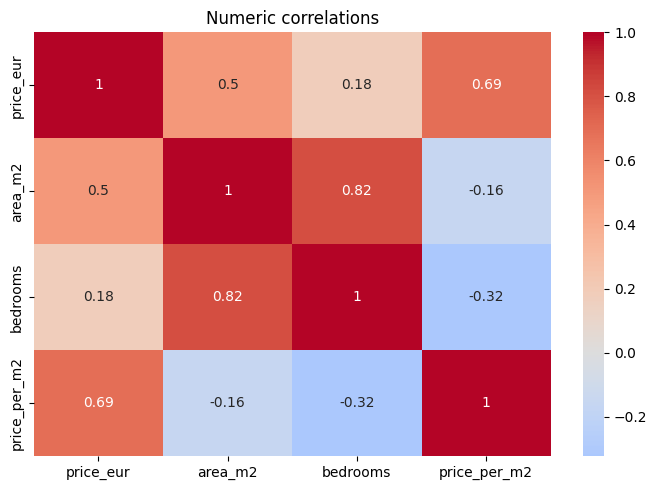

In [26]:
numeric_cols = ['price_eur', 'area_m2', 'bedrooms', 'price_per_m2']
plt.figure(figsize=(7,5)); sns.heatmap(real[numeric_cols].corr(), annot=True, cmap='coolwarm', center=0); plt.title('Numeric correlations'); plt.tight_layout(); plt.show()

This chart shows correlations between the numeric columns. Values close to 1 mean a positive relationship, values close to -1 mean a negative relationship, and values close to 0 mean a weak linear relationship.

## 5. Conclusion and limitations
After running the notebook, I can summarize the number of real apartment listings and the differences between cities. These are **asking prices**, not confirmed sale prices. Some listings have missing or incorrect locations, and a few may be duplicates. Professional appraisals and synthetic examples are not included in the apartment model.


## 6. Machine Learning — Apartment Price Prediction
We will use apartment size, bedrooms, and city to predict asking prices. The model is trained only on real listings.

### 6.1 Select Features and Target

In [27]:
features = ['area_m2', 'bedrooms', 'city_model']
X = real[features].copy()
y = real['price_eur'].copy()

print('Features:', X.shape)
print('Target:', y.shape)
display(X.head())

Features: (2432, 3)
Target: (2432,)


,area_m2,bedrooms,city_model
95,59.0,1.0,Herceg Novi
96,230.0,5.0,Herceg Novi
97,58.0,1.0,Kotor
98,93.0,2.0,Herceg Novi
99,178.0,3.0,Herceg Novi


I selected apartment size, number of bedrooms, and city as features. The target is the asking price in euros. I did not use price per m² because it is calculated from the target price.

### 6.2 Check Missing Values

In [28]:
print(X.isnull().sum())

area_m2         0
bedrooms      253
city_model      0
dtype: int64


Some listings have missing bedroom values. I will fill these using the median calculated from the training data, so I can keep the apartments without using information from the test set.

### 6.3 Encode Cities and Prepare the Data

In [29]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features = ['area_m2', 'bedrooms']
category_features = ['city_model']

preprocessor = ColumnTransformer([
    ('num', SimpleImputer(strategy='median'), numeric_features),
    ('city', OneHotEncoder(handle_unknown='ignore'), category_features)
])

I used one-hot encoding to turn city names into numbers. Missing numeric values will be filled using the training data. The preprocessing steps are included in the model pipeline.

### 6.4 Train/Test Split

In [30]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print('Training:', X_train.shape)
print('Testing:', X_test.shape)

Training: (1945, 3)
Testing: (487, 3)


I split the data into 80% for training and 20% for testing. The test apartments are used to check how well the model predicts unseen prices.

### 6.5 Linear Regression

In [31]:
from sklearn.linear_model import LinearRegression

linear_model = Pipeline([
    ('preprocessing', preprocessor),
    ('model', LinearRegression())
])

linear_model.fit(X_train, y_train)
linear_predictions = linear_model.predict(X_test)
print('Linear Regression trained.')

Linear Regression trained.


Linear Regression is my first model. It learns a relationship between the selected apartment features and asking prices.

### 6.6 Evaluate Linear Regression

In [32]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

linear_mae = mean_absolute_error(y_test, linear_predictions)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predictions))
linear_r2 = r2_score(y_test, linear_predictions)

print('MAE:', round(linear_mae, 2))
print('RMSE:', round(linear_rmse, 2))
print('R²:', round(linear_r2, 3))

MAE: 55962.91
RMSE: 88855.21
R²: 0.642


MAE is the average absolute prediction error in euros. RMSE gives more weight to larger errors. R² shows how much of the variation in prices the model explains on the test set.

### 6.7 Random Forest Regression

In [33]:
from sklearn.ensemble import RandomForestRegressor

forest_model = Pipeline([
    ('preprocessing', preprocessor),
    ('model', RandomForestRegressor(n_estimators=100, random_state=42, min_samples_leaf=2))
])

forest_model.fit(X_train, y_train)
forest_predictions = forest_model.predict(X_test)

forest_mae = mean_absolute_error(y_test, forest_predictions)
forest_rmse = np.sqrt(mean_squared_error(y_test, forest_predictions))
forest_r2 = r2_score(y_test, forest_predictions)

print('MAE:', round(forest_mae, 2))
print('RMSE:', round(forest_rmse, 2))
print('R²:', round(forest_r2, 3))

MAE: 49210.31
RMSE: 81696.73
R²: 0.697


Random Forest combines many decision trees. I will compare its test results with Linear Regression to see which model works better for this dataset.

### 6.8 Compare Models

In [34]:
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest'],
    'MAE (EUR)': [linear_mae, forest_mae],
    'RMSE (EUR)': [linear_rmse, forest_rmse],
    'R2': [linear_r2, forest_r2]
})
display(results.round(2))

,Model,MAE (EUR),RMSE (EUR),R2
0,Linear Regression,55962.91,88855.21,0.64
1,Random Forest,49210.31,81696.73,0.70


Lower MAE and RMSE mean smaller errors. Higher R² is generally better. I will choose the model based on its test results, not only its training performance.

### 6.9 Actual vs Predicted Prices

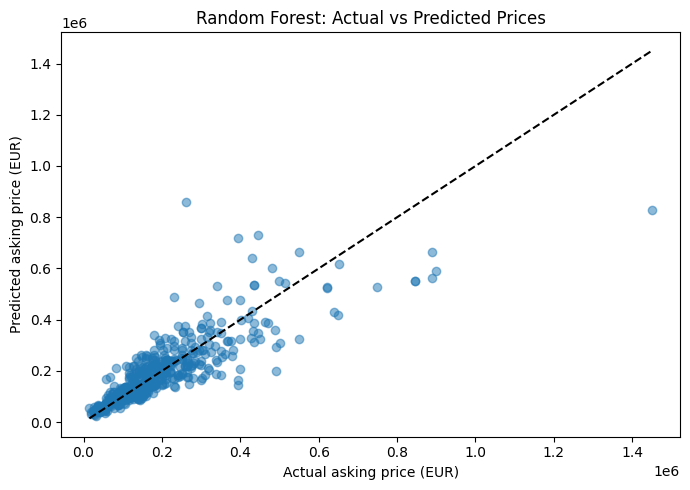

In [35]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))
plt.scatter(y_test, forest_predictions, alpha=0.5)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'k--')
plt.xlabel('Actual asking price (EUR)')
plt.ylabel('Predicted asking price (EUR)')
plt.title('Random Forest: Actual vs Predicted Prices')
plt.tight_layout()
plt.show()

Points close to the dashed line show more accurate predictions. Points farther away show larger errors. These are asking prices, not confirmed sale prices.

### 6.10 Example Predictions

In [36]:
examples = X_test.head(5).copy()
examples['actual_price_eur'] = y_test.loc[examples.index]
examples['predicted_price_eur'] = forest_model.predict(X_test.head(5)).round(0)
display(examples)

,area_m2,bedrooms,city_model,actual_price_eur,predicted_price_eur
537,47.0,1.0,Budva,263000.0,176102.0
2675,135.0,4.0,Bijelo Polje,148000.0,137878.0
780,50.0,NaN,Podgorica,126000.0,139374.0
1554,39.0,1.0,Podgorica,130000.0,111766.0
2665,148.0,5.0,Šavnik,114000.0,129510.0


This table compares actual asking prices and predicted prices for five apartments from the test set. The model is only a first estimate and has limitations.

## 7. Improving the Random Forest Model

I will try a few simple Random Forest settings and compare them on the same test set. I will keep the original model if the new settings do not improve the results. These predictions estimate **asking prices**, not confirmed sale prices.


In [37]:
# Compare a few Random Forest settings
settings = [
    {'n_estimators': 100, 'min_samples_leaf': 2, 'max_depth': None},
    {'n_estimators': 150, 'min_samples_leaf': 4, 'max_depth': 15},
    {'n_estimators': 200, 'min_samples_leaf': 3, 'max_depth': 20}
]

comparison = []
for setting in settings:
    candidate = Pipeline([
        ('preprocessing', preprocessor),
        ('model', RandomForestRegressor(random_state=42, n_jobs=-1, **setting))
    ])
    candidate.fit(X_train, y_train)
    predictions = candidate.predict(X_test)
    comparison.append({
        'Trees': setting['n_estimators'],
        'Min leaf': setting['min_samples_leaf'],
        'Max depth': str(setting['max_depth']),
        'MAE (EUR)': round(mean_absolute_error(y_test, predictions), 2),
        'R2': round(r2_score(y_test, predictions), 3)
    })

comparison_df = pd.DataFrame(comparison)
display(comparison_df)


,Trees,Min leaf,Max depth,MAE (EUR),R2
0,100,2,None,49210.31,0.697
1,150,4,15,49687.54,0.695
2,200,3,20,49411.55,0.691


The MAE shows the average error in euros. A lower MAE is better. This is a small experiment, not a final evaluation: choosing settings using the test set can make the reported performance too optimistic.


## 8. Try a Price Prediction

Here I can enter the area, number of bedrooms, and city of an apartment. The model gives an estimated asking price in euros. I use the original trained Random Forest model so the earlier test results remain comparable.


In [38]:
# Example: change these three values to try another apartment
apartment_area = 65
apartment_bedrooms = 2
apartment_city = 'Podgorica'

new_apartment = pd.DataFrame({
    'area_m2': [apartment_area],
    'bedrooms': [apartment_bedrooms],
    'city_model': [apartment_city]
})

estimated_price = forest_model.predict(new_apartment)[0]
print('City:', apartment_city)
print('Area:', apartment_area, 'm²')
print('Bedrooms:', apartment_bedrooms)
print('Estimated asking price: €{:,.0f}'.format(estimated_price))
print('Estimated asking price per m²: €{:,.0f}'.format(estimated_price / apartment_area))


City: Podgorica
Area: 65 m²
Bedrooms: 2
Estimated asking price: €159,459
Estimated asking price per m²: €2,453


## 9. Final Notes

This is an early version of Valora AI. The results depend on the quality of the online listings and on the limited information used by the model. In the future, I would like to add neighborhood, property condition, and verified professional appraisal data. Before using the model in practice, I would also check performance on a separate validation dataset.
